# 05 · The lever: GLP-1 and SGLT2 drugs, how much they're used, what they cost

**Part B of the story.** Notebook 04 found who keeps coming back to hospital. This notebook describes the tool that could change that: GLP-1 and SGLT2 drugs, which cut hospitalizations in large trials and are now recommended for diabetic patients with heart or kidney disease.

Three questions, each answered from **one consistent source**:

1. **How has their use changed?** CMS Part D national totals, 2013–2024 (same file every year).
2. **Where does the money go today?** CMS Part D spending by drug, 2020–2024.
3. **What does a year of treatment cost?** Gross Medicare cost per 30-day fill (CMS, 2024) vs. the new Medicare negotiated prices (CMS fact sheets).

The output, the annual cost of treatment, is the cost side of notebook 06.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make src/ importable when run from notebooks/

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from src.config import ROOT, PROCESSED, FIGURES, SERIES, MUTED, INK2, CLASS_ORDER, ADVANCED, style, update_results
style()

nat = pd.read_parquet(PROCESSED / "national_by_year.parquet")
spend = pd.read_parquet(PROCESSED / "spending_by_brand.parquet")
spend = spend[~spend.weight_loss_brand]
claims = pd.read_parquet(PROCESSED / "prescriber_claims.parquet")
state = pd.read_parquet(PROCESSED / "state_claims.parquet")
county = pd.read_parquet(PROCESSED / "county_burden.parquet")
A = pd.read_csv(ROOT / "reference" / "assumptions.csv").set_index("parameter")
A[["base", "unit", "source"]]

,base,unit,source
parameter,,,
rrr_hospitalization,0.110,relative reduction in all-cause hospitalization,EMPA-REG OUTCOME (empagliflozin vs placebo): a...
cost_per_admission_hcup_2018,15200.000,USD per readmission in 2018 dollars (all payers),AHRQ HCUP Statistical Brief #278: average 30-d...
price_sglt2_list_30d,573.000,USD per 30-day supply,"Jardiance 2023 list price, CMS negotiated-pric..."
price_sglt2_mfp_30d,197.000,USD per 30-day supply (2026),Jardiance Medicare negotiated price effective ...
price_sglt2b_mfp_30d,178.500,USD per 30-day supply (2026),Farxiga Medicare negotiated price effective Ja...
price_glp1_list_30d,959.000,USD per 30-day supply,"Ozempic/Rybelsus/Wegovy 2024 list price, CMS 2..."
price_glp1_mfp_30d,274.000,USD per 30-day supply (2027),Semaglutide Medicare negotiated price effectiv...
future_admissions_factor,1.000,next-year admissions as a share of past-year a...,Assumption: next year's admissions match the p...
benchmark_readmission_diabetes,0.182,30-day readmission rate of hospitalized diabet...,"Rubin & Shah, Current Diabetes Reports 2021: m..."


## 1. Use over time: 1.5% of claims in 2013, a third in 2024

Same CMS file every year, same definitions. "Newer" = any product containing a GLP-1 or SGLT2 drug (combination pills included). Weight-loss brands (Wegovy, Zepbound, Saxenda) are excluded.

In [2]:
trend = nat.groupby("year").apply(lambda d: pd.Series({
    "claims_M": d.Tot_Clms.sum() / 1e6, "cost_B": d.Tot_Drug_Cst.sum() / 1e9,
    "newer_share_claims": 100 * d.loc[d.newer, "Tot_Clms"].sum() / d.Tot_Clms.sum(),
    "newer_share_cost": 100 * d.loc[d.newer, "Tot_Drug_Cst"].sum() / d.Tot_Drug_Cst.sum()}), include_groups=False).round(1)
trend

,claims_M,cost_B,newer_share_claims,newer_share_cost
year,,,,
2013,75.1,10.4,1.5,5.4
2014,80.8,14.0,2.1,6.7
2015,84.2,17.4,3.2,9.3
2016,87.6,20.2,4.3,12.5
2017,89.2,23.1,5.5,16.5
2018,89.5,26.6,7.0,20.9
2019,90.9,30.5,9.2,26.6
2020,92.8,34.3,11.7,33.6
2021,94.5,39.4,15.2,41.5


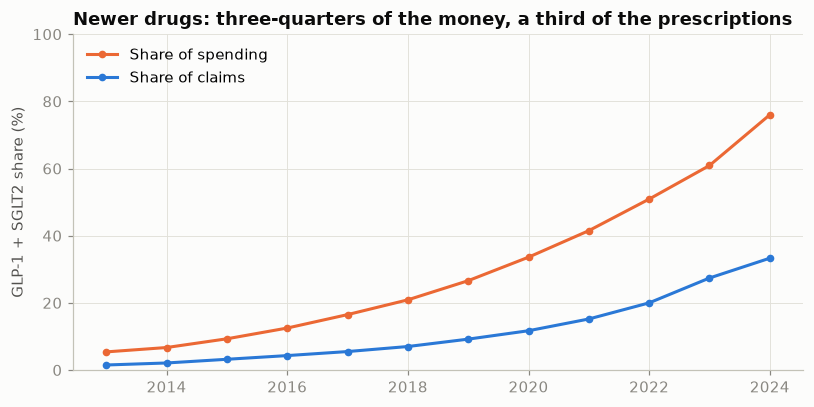

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(trend.index, trend.newer_share_cost, color=SERIES[1], lw=2, marker="o", ms=4, label="Share of spending")
ax.plot(trend.index, trend.newer_share_claims, color=SERIES[0], lw=2, marker="o", ms=4, label="Share of claims")
ax.set_ylim(0, 100); ax.set_ylabel("GLP-1 + SGLT2 share (%)"); ax.legend(loc="upper left")
ax.set_title("Newer drugs: three-quarters of the money, a third of the prescriptions")
plt.tight_layout(); plt.savefig(FIGURES / "05_trend.png", dpi=160); plt.show()

In the hospital data (1999–2008) none of these patients were on either class: the first GLP-1 (exenatide) was approved in 2005 and the first SGLT2 (canagliflozin) in 2013. By 2024 they're **76% of Medicare diabetes drug spending but only 33% of claims**, because they cost far more per prescription. That price gap is the whole question for notebook 06.

## 2. Where the money goes, 2020–2024

In [4]:
years = range(2020, 2025)
long = pd.concat([spend.groupby("drug_class")[[f"Tot_Spndng_{y}", f"Tot_Clms_{y}"]].sum()
                     .set_axis(["spend", "claims"], axis=1).assign(year=y) for y in years]).reset_index()
pivot = long.pivot(index="year", columns="drug_class", values="spend").fillna(0) / 1e9
pivot[[c for c in CLASS_ORDER if c in pivot and pivot[c].max() > 0.3]].round(1)

drug_class,Biguanide (metformin),Insulin,DPP-4 inhibitor,SGLT2 inhibitor,GLP-1 / GIP-GLP-1 agonist
year,,,,,
2020,0.6,15.2,6.6,4.0,7.2
2021,0.6,15.3,6.9,6.0,10.2
2022,0.7,15.1,6.9,9.4,14.2
2023,0.9,15.6,6.8,14.2,22.6
2024,0.7,7.3,6.2,17.9,27.6


## 3. What a year of treatment costs

**Gross cost** = what Medicare Part D paid per 30-day fill in 2024 (total drug cost ÷ 30-day fills, CMS national file), times 12. It's before manufacturer rebates, which are confidential.

**Negotiated price** = the price Medicare negotiated under the Inflation Reduction Act: Jardiance $197 and Farxiga $178.50 a month from 2026, semaglutide (Ozempic, Rybelsus) $274 a month from 2027. Sources are in `reference/assumptions.csv`.

In [5]:
y24 = nat[nat.year == 2024]
BRANDS = {"Jardiance": "SGLT2", "Farxiga": "SGLT2", "Ozempic": "GLP-1", "Trulicity": "GLP-1", "Mounjaro": "GLP-1", "Rybelsus": "GLP-1"}
NEGOTIATED = {"Jardiance": A.loc["price_sglt2_mfp_30d", "base"], "Farxiga": A.loc["price_sglt2b_mfp_30d", "base"],
              "Ozempic": A.loc["price_glp1_mfp_30d", "base"], "Rybelsus": A.loc["price_glp1_mfp_30d", "base"]}
cost = (y24[y24.Brnd_Name.isin(BRANDS)].groupby("Brnd_Name")
          .agg(patients=("Tot_Benes", "sum"), cost=("Tot_Drug_Cst", "sum"), fills=("Tot_30day_Fills", "sum"))
          .assign(cls=lambda d: d.index.map(BRANDS), gross_30d=lambda d: d.cost / d.fills)
          .assign(gross_year=lambda d: 12 * d.gross_30d, negotiated_30d=lambda d: d.index.map(NEGOTIATED).astype(float))
          .assign(negotiated_year=lambda d: 12 * d.negotiated_30d)
          .sort_values("cost", ascending=False))
cost[["cls", "patients", "gross_30d", "gross_year", "negotiated_30d", "negotiated_year"]].round(0)

,cls,patients,gross_30d,gross_year,negotiated_30d,negotiated_year
Brnd_Name,,,,,,
Ozempic,GLP-1,1951892.0,903.0,10840.0,274.0,3288.0
Jardiance,SGLT2,2542517.0,541.0,6491.0,197.0,2364.0
Mounjaro,GLP-1,894243.0,1040.0,12475.0,NaN,NaN
Trulicity,GLP-1,788414.0,948.0,11381.0,NaN,NaN
Farxiga,SGLT2,1268791.0,538.0,6460.0,178.0,2142.0
Rybelsus,GLP-1,309850.0,916.0,10989.0,274.0,3288.0


In [6]:
def gross_year(cls):
    c = cost[cost.cls == cls]
    return 12 * c.cost.sum() / c.fills.sum()

ANNUAL = {
    "SGLT2 · negotiated (2026)": 12 * A.loc["price_sglt2_mfp_30d", "base"],
    "GLP-1 · negotiated (2027)": 12 * A.loc["price_glp1_mfp_30d", "base"],
    "SGLT2 · gross 2024": gross_year("SGLT2"),
    "GLP-1 · gross 2024": gross_year("GLP-1"),
}
pd.Series(ANNUAL).round(0).rename("annual cost per patient ($)")

SGLT2 · negotiated (2026)     2364.0
GLP-1 · negotiated (2027)     3288.0
SGLT2 · gross 2024            6481.0
GLP-1 · gross 2024           11313.0
Name: annual cost per patient ($), dtype: float64

A year of an SGLT2 drug costs Medicare about **$6,500 gross** today and **$2,364 at the negotiated price**. GLP-1 drugs cost more: about **$11,000 gross**, **$3,288 negotiated**. These four numbers are the price scenarios in notebook 06.

## 4. Supporting context: which prescribers use them least

Not part of the main argument. It's kept because it says **who** would carry out a recommendation: primary care writes most diabetes prescriptions. Computed from the 2024 prescriber file, which misses rows under 11 claims, so the shares are approximate.

In [7]:
con = duckdb.connect(); con.register("claims", claims)
spec = con.sql('''
    SELECT Prscrbr_Type AS specialty, COUNT(DISTINCT Prscrbr_NPI) AS prescribers, SUM(Tot_Clms) AS diabetes_claims,
           ROUND(100 * SUM(CASE WHEN drug_class IN ('GLP-1 / GIP-GLP-1 agonist', 'SGLT2 inhibitor') THEN Tot_Clms END) / SUM(Tot_Clms), 1) AS advanced_pct,
           ROUND(100 * SUM(CASE WHEN drug_class = 'GLP-1 / GIP-GLP-1 agonist' THEN Tot_Clms END) / SUM(Tot_Clms), 1) AS glp1_pct,
           ROUND(100 * SUM(CASE WHEN drug_class = 'SGLT2 inhibitor' THEN Tot_Clms END) / SUM(Tot_Clms), 1) AS sglt2_pct,
           ROUND(100 * SUM(CASE WHEN drug_class IN ('Biguanide (metformin)', 'Sulfonylurea') THEN Tot_Clms END) / SUM(Tot_Clms), 1) AS metformin_su_pct
    FROM claims GROUP BY 1 HAVING SUM(Tot_Clms) >= 50000 ORDER BY diabetes_claims DESC
''').df()
spec["specialty"] = spec.specialty.replace({"Student in an Organized Health Care Education/Training Program": "Medical trainee"})
spec["share_of_all_claims_pct"] = (100 * spec.diabetes_claims / claims.Tot_Clms.sum()).round(1)
spec.head(8)

,specialty,prescribers,diabetes_claims,advanced_pct,glp1_pct,sglt2_pct,metformin_su_pct,share_of_all_claims_pct
0,Family Practice,82336,32009158.0,31.0,18.2,12.8,48.6,30.7
1,Internal Medicine,62990,28941734.0,31.1,17.0,14.1,45.6,27.8
2,Nurse Practitioner,86027,18997657.0,36.9,21.4,15.5,41.0,18.2
3,Endocrinology,6076,9379129.0,40.0,27.1,12.8,23.4,9.0
4,Physician Assistant,26841,6146304.0,38.0,22.5,15.5,41.5,5.9
5,General Practice,4723,2387470.0,19.5,8.1,11.4,53.7,2.3
6,Cardiology,13515,1637844.0,82.6,9.6,73.1,13.4,1.6
7,Nephrology,6784,1052798.0,79.7,8.0,71.8,11.0,1.0


In [8]:
# State burden vs. adoption: used only by the appendix notebook (07)
con.register("state", state); con.register("county", county)
burden = con.sql('''SELECT stateabbr, statedesc, SUM(adults_with_diabetes) AS adults_with_diabetes,
                           ROUND(100 * SUM(adults_with_diabetes) / SUM(totalpop18plus), 1) AS diabetes_prev_pct,
                           ROUND(SUM(OBESITY * totalpop18plus) / SUM(totalpop18plus), 1) AS obesity_prev_pct
                    FROM county GROUP BY 1, 2''').df()
adopt = con.sql('''SELECT Prscrbr_Geo_Desc AS statedesc, SUM(Tot_Clms) AS diabetes_claims,
                          ROUND(100 * SUM(CASE WHEN drug_class IN ('GLP-1 / GIP-GLP-1 agonist', 'SGLT2 inhibitor') THEN Tot_Clms END) / SUM(Tot_Clms), 1) AS advanced_pct
                   FROM state GROUP BY 1''').df()
st = burden.merge(adopt, on="statedesc")
med_prev, med_adopt = st.diabetes_prev_pct.median(), st.advanced_pct.median()
st["quadrant"] = np.select(
    [(st.diabetes_prev_pct > med_prev) & (st.advanced_pct < med_adopt), (st.diabetes_prev_pct > med_prev) & (st.advanced_pct >= med_adopt),
     (st.diabetes_prev_pct <= med_prev) & (st.advanced_pct < med_adopt)],
    ["High burden, low adoption", "High burden, high adoption", "Low burden, low adoption"], "Low burden, high adoption")
st.to_parquet(PROCESSED / "state_summary.parquet", index=False)
spec.to_parquet(PROCESSED / "specialty_summary.parquet", index=False)
print(len(st), "states + DC matched")

49 states + DC matched


In [9]:
nat_adv = 100 * claims.loc[claims.drug_class.isin(ADVANCED), "Tot_Clms"].sum() / claims.Tot_Clms.sum()
update_results("lever", {
    "trend": trend.reset_index().to_dict("records"),
    "spend_by_class": long[["year", "drug_class", "spend", "claims"]].to_dict("records"),
    "brand_costs": cost.reset_index()[["Brnd_Name", "cls", "patients", "gross_30d", "gross_year", "negotiated_30d", "negotiated_year"]].round(0).to_dict("records"),
    "annual_cost": {k: round(v) for k, v in ANNUAL.items()},
    "specialties": spec.head(12).to_dict("records"),
})
update_results("market", {"specialties": spec.head(12).to_dict("records"), "national_advanced_pct": round(nat_adv, 1),
                          "states": st.to_dict("records"),
                          "state_medians": {"prev": med_prev, "adopt": med_adopt, "corr": round(st[["diabetes_prev_pct", "advanced_pct"]].corr().iloc[0, 1], 2)}})
print("saved")

saved
